# Estudo da resistência celular em tumores a partir de um modelo de competição de Lotka-Volterra.

**Desenvolvedoras:** Ana Luiza de Lima Silva e Mariana Bueno Cavalcanti

**Professor responsável:** Dr. Vinicius Francisco Wasques

**Disciplina:** Equações diferenciais - 2° semestre de 2026

## Importação de bibliotecas e definição de parâmetros

In [10]:
import numpy as np                    
import pandas as pd                  
import matplotlib.pyplot as plt     
from pathlib import Path

from matplotlib.lines import Line2D           
from matplotlib.colors import ListedColormap  
from matplotlib.patches import Patch

In [11]:
CORES = ["#e4572e", "#f2c14e", "#7b3fa0", "#2a9d8f", "#264653"]   
Path("resultados").mkdir(exist_ok=True)       


cen1 = dict(alpha=0.5, beta=2.0, rx=0.03, ry=0.02, rd=0.1)    
cen2 = dict(alpha=1.5, beta=0.7, rx=0.03, ry=0.02, rd=0.1)    
dose_cont = dict(alpha=0.5, beta=1.5, rx=0.04, ry=0.03, rd=0.05)  

A, delta = 0.8, 0.4        
dt = 0.01                  
EPS = 1e-3                 
T_MAX = 3000               
c_x, c_y = "#2a7fb8", "#d1495b"   

In [12]:
def f(u, K, p):
    x, y = u
    return np.array([p["rx"]*x*(1 - x - p["alpha"]*y) - K*p["rd"]*x,   
                     p["ry"]*y*(1 - y - p["beta"]*x)])                 


def equilibrios(p, K):
    # Equilíbrios com x, y >= 0.
    pts = [(0, 0), (0, 1)]                                   
    xs = 1 - K*p["rd"]/p["rx"]                               
    if xs > 0:
        pts.append((xs, 0))
    den = 1 - p["alpha"]*p["beta"]                           
    if abs(den) > 1e-12:
        xi = (1 - p["alpha"] - K*p["rd"]/p["rx"]) / den
        yi = 1 - p["beta"]*xi
        if xi > 0 and yi > 0:
            pts.append((xi, yi))
    return pts


def autovalores(x, y, K, p):
    J = np.array([[p["rx"]*(1 - 2*x - p["alpha"]*y) - K*p["rd"], -p["alpha"]*p["rx"]*x],
                  [-p["beta"]*p["ry"]*y,                          p["ry"]*(1 - 2*y - p["beta"]*x)]])
    return np.linalg.eigvals(J)


def estavel(x, y, K, p):
    return np.all(autovalores(x, y, K, p).real < 0)



In [13]:
def rk4(u, K, p):
    k1 = f(u, K, p)
    k2 = f(u + dt/2*k1, K, p)
    k3 = f(u + dt/2*k2, K, p)
    k4 = f(u + dt*k3, K, p)
    return np.maximum(u + dt/6*(k1 + 2*k2 + 2*k3 + k4), 0)     


def simular(p, x0, y0, T, modo, parar=False):
    u, K = np.array([x0, y0]), 0.0
    U, Ks = [], []
    for i in range(int(T/dt) + 1):
        if modo == "sem":
            K = 0.0
        elif modo == "sempre":
            K = 1.0
        else:                                   
            if u.sum() >= A:
                K = 1.0                         
            elif u.sum() <= A - delta:
                K = 0.0                         
        U.append(u); Ks.append(K)
        if parar and (u[1] < EPS or u[1] >= A):
            break                               
        u = rk4(u, K, p)
    U = np.array(U)
    return dict(t=np.arange(len(U))*dt, x=U[:, 0], y=U[:, 1], K=np.array(Ks))


def desfecho(s):
    ext, fal = np.flatnonzero(s["y"] < EPS), np.flatnonzero(s["y"] >= A)
    if len(ext) and (not len(fal) or ext[0] <= fal[0]):
        nome, i = "extinção", ext[0]
    elif len(fal):
        nome, i = "falha", fal[0]
    else:
        return dict(desfecho="sem desfecho", tempo=np.nan, pct_medicado=np.nan, religamentos=np.nan)
    K = s["K"][:i + 1]
    return dict(desfecho=nome, tempo=round(s["t"][i], 1), pct_medicado=round(100*K.mean(), 1),
                religamentos=int(np.sum(np.diff(K) == 1)))

In [14]:
def campo(ax, X, Y, U, V, seta=False):
     
    ax.figure.canvas.draw() 
    du = U * ax.bbox.width / np.ptp(ax.get_xlim())
    dv = V * ax.bbox.height / np.ptp(ax.get_ylim())
    n = np.hypot(du, dv); n[n == 0] = 1 
    h = 4 if seta else 0    
    ax.quiver(X, Y, du/n, dv/n, angles="uv", pivot="mid", scale_units="width", scale=40, width=0.002,
    headwidth=h, headlength=1.2*h, headaxislength=h, color="#7fb3e6", zorder=1)

def equilibrios_no_grafico(ax, p, K):
    for x, y in equilibrios(p, K):
        ax.plot(x, y, "o", mfc="k" if estavel(x, y, K, p) else "w", mec="k", ms=7, zorder=5)

In [15]:
def preparar(axs, titulos, lim=1.15):
    for ax, tit in zip(np.ravel(axs), titulos):
        ax.set(xlim=(0, lim), ylim=(0, lim), title=tit, xlabel="sensíveis (x)", ylabel="resistentes (y)")


def plano_fase(ax, p, K, condicoes=(), T=1000, modo="sem", lim=1.15, legenda=False):
    g = np.linspace(0.03, lim - 0.03, 22)
    X, Y = np.meshgrid(g, g)                                     
    U, V = f((X, Y), K, p)                                        
    campo(ax, X, Y, U, V)                                        
    xs = np.linspace(0, lim, 200)
    ax.plot(xs, 1 - p["beta"]*xs, c=c_y, lw=1.6)                  
    ys = (1 - xs - K*p["rd"]/p["rx"]) / p["alpha"]               
    if np.any(ys >= 0):
        ax.plot(xs, np.where(ys >= 0, ys, np.nan), c=c_x, lw=1.6)
    ax.axvline(0, c=c_x, lw=1.6); ax.axhline(0, c=c_y, lw=1.6)   

    for (x0, y0), cor in zip(condicoes, CORES):                   
        s = simular(p, x0, y0, T, modo)
        tx, ty = s["x"][::50], s["y"][::50]
        ax.plot(tx, ty, c=cor, lw=1.8, zorder=3)
        ax.plot(x0, y0, "o", c=cor, ms=4, zorder=4)               
        m = len(tx) // 8                                          
        ax.annotate("", xy=(tx[m + 1], ty[m + 1]), xytext=(tx[m], ty[m]),
                    arrowprops=dict(arrowstyle="->", color=cor, lw=1.4), zorder=4)

    for x, y in equilibrios(p, K):                                
        ax.plot(x, y, "o", mfc="k" if estavel(x, y, K, p) else "w", mec="k", ms=8, zorder=5)

    if legenda:
        ax.legend(handles=[Line2D([], [], c=c_x, lw=1.6, label=r"isóclina de $x$ ($\dot x=0$)"),
                           Line2D([], [], c=c_y, lw=1.6, label=r"isóclina de $y$ ($\dot y=0$)"),
                           Line2D([], [], marker="o", mfc="k", mec="k", ls="", label="equilíbrio estável"),
                           Line2D([], [], marker="o", mfc="w", mec="k", ls="", label="equilíbrio instável")],
                  fontsize=7, loc="upper right", framealpha=0.95)

## Verificando o equilíbrio em cada um dos casos

In [16]:
linhas = []
for nome, p, K in [("Sem fármaco, Cenário 1", cen1, 0), ("Sem fármaco, Cenário 2", cen2, 0),
                   ("Dose contínua", dose_cont, 1), ("Fármaco ligado, Cenário 1", cen1, 1), ("Fármaco ligado, Cenário 2", cen2, 1)]:
    for x, y in equilibrios(p, K):
        ev = autovalores(x, y, K, p).real
        comp = "nenhuma célula" if x == 0 and y == 0 else "só sensíveis" if y == 0 else "só resistentes" if x == 0 else "coexistência"
        est = "estável" if np.all(ev < 0) else "instável (sela)" if ev.min() < 0 < ev.max() else "instável"
        linhas.append([nome, K, f"({x:.2f}; {y:.2f})", comp, est])
tab_eq = pd.DataFrame(linhas, columns=["Caso", "K", "(x*, y*)", "Composição", "Estabilidade"])
tab_eq.to_csv("resultados/tabela_equilibrios.csv", index=False)
tab_eq

,Caso,K,"(x*, y*)",Composição,Estabilidade
0,"Sem fármaco, Cenário 1",0,(0.00; 0.00),nenhuma célula,instável
1,"Sem fármaco, Cenário 1",0,(0.00; 1.00),só resistentes,instável (sela)
2,"Sem fármaco, Cenário 1",0,(1.00; 0.00),só sensíveis,estável
3,"Sem fármaco, Cenário 2",0,(0.00; 0.00),nenhuma célula,instável
4,"Sem fármaco, Cenário 2",0,(0.00; 1.00),só resistentes,estável
5,"Sem fármaco, Cenário 2",0,(1.00; 0.00),só sensíveis,instável (sela)
6,Dose contínua,1,(0.00; 0.00),nenhuma célula,instável (sela)
7,Dose contínua,1,(0.00; 1.00),só resistentes,estável
8,"Fármaco ligado, Cenário 1",1,(0.00; 0.00),nenhuma célula,instável (sela)
9,"Fármaco ligado, Cenário 1",1,(0.00; 1.00),só resistentes,estável


## Simulação sem fármacos

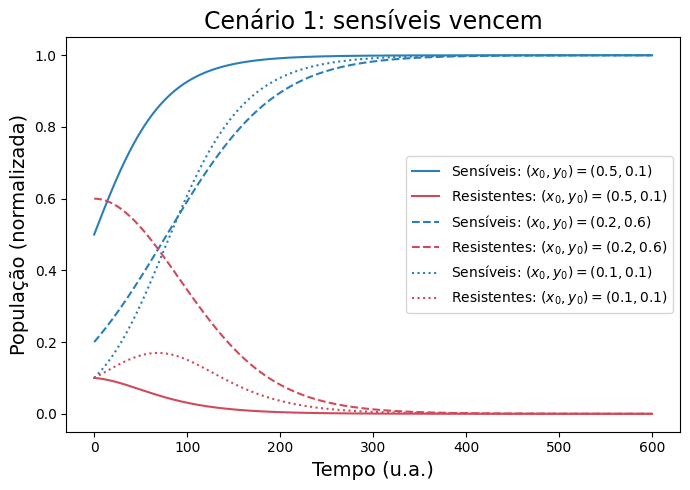

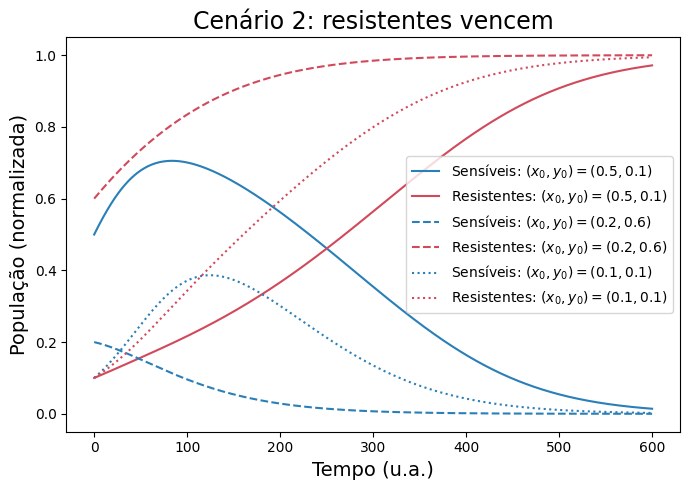

In [19]:
condicoes = [(0.5, 0.1), (0.2, 0.6), (0.1, 0.1)]
estilos = ["-", "--", ":"]

# Cenário 1
fig, ax = plt.subplots(figsize=(7, 5))

for (x0, y0), ls in zip(condicoes, estilos):
    s = simular(cen1, x0, y0, 600, "sem")

    ax.plot(
        s["t"][::50], s["x"][::50],
        c=c_x, ls=ls,
        label=f"Sensíveis: $(x_0,y_0)=({x0},{y0})$"
    )

    ax.plot(
        s["t"][::50], s["y"][::50],
        c=c_y, ls=ls,
        label=f"Resistentes: $(x_0,y_0)=({x0},{y0})$"
    )

ax.set_title("Cenário 1: sensíveis vencem",fontsize=17)
ax.set_xlabel("Tempo (u.a.)", fontsize=14)
ax.set_ylabel("População (normalizada)",fontsize=14)
ax.legend(fontsize=10)

plt.tight_layout()
plt.savefig("resultados/cenario1_sem_farmaco.pdf", bbox_inches="tight")
plt.show()


# Cenário 2
fig, ax = plt.subplots(figsize=(7, 5))

for (x0, y0), ls in zip(condicoes, estilos):
    s = simular(cen2, x0, y0, 600, "sem")

    ax.plot(
        s["t"][::50], s["x"][::50],
        c=c_x, ls=ls,
        label=f"Sensíveis: $(x_0,y_0)=({x0},{y0})$"
    )

    ax.plot(
        s["t"][::50], s["y"][::50],
        c=c_y, ls=ls,
        label=f"Resistentes: $(x_0,y_0)=({x0},{y0})$"
    )

ax.set_title("Cenário 2: resistentes vencem", fontsize=17)
ax.set_xlabel("Tempo (u.a.)", fontsize=14)
ax.set_ylabel("População (normalizada)", fontsize=14)
ax.legend(fontsize=10)

plt.tight_layout()
plt.savefig("resultados/cenario2_sem_farmaco.pdf", dpi=300, bbox_inches="tight", pad_inches=0.02)
plt.show()

## Comparandos os cenários sem aplicação, com aplicação contínua e intermitente de terapias

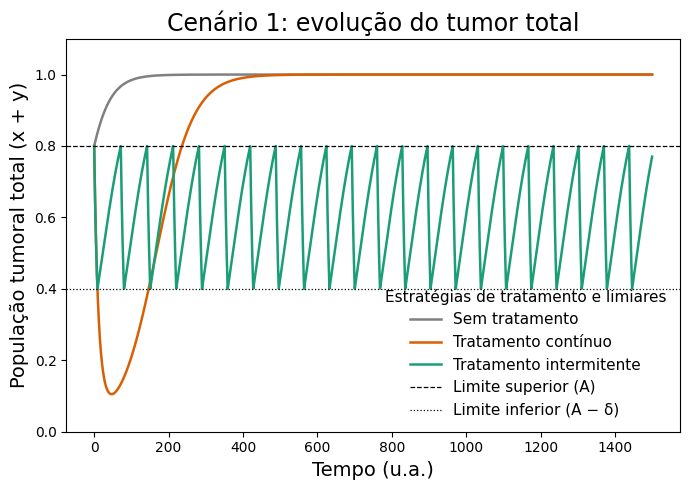

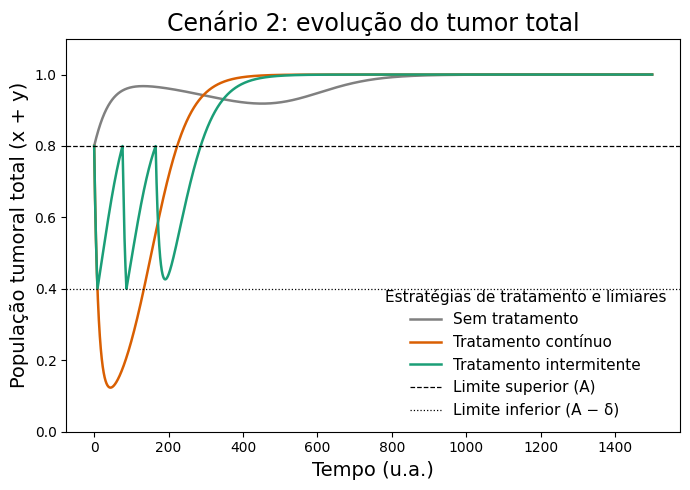

In [20]:
y0 = 0.05

for p, nome, arquivo in [
    (cen1, "Cenário 1", "fig2_tumor_total_cenario1"),
    (cen2, "Cenário 2", "fig2_tumor_total_cenario2")
]:

    fig, ax = plt.subplots(figsize=(7, 5))

    # Estratégias de tratamento
    estrategias = [
        ("sem", "gray", "Sem tratamento"),
        ("sempre", "#d95f02", "Tratamento contínuo"),
        ("intermitente", "#1b9e77", "Tratamento intermitente")
    ]

    for modo, cor, legenda in estrategias:

        s = simular(p, A - y0, y0, 1500, modo)

        ax.plot(
            s["t"][::20],
            (s["x"] + s["y"])[::20],
            c=cor,
            lw=1.8,
            label=legenda
        )

    # Limiares de referência
    ax.axhline(
        A,
        c="black",
        ls="--",
        lw=0.9,
        label="Limite superior (A)"
    )

    ax.axhline(
        A - delta,
        c="black",
        ls=":",
        lw=0.9,
        label="Limite inferior (A − δ)"
    )

    # Eixos e título
    ax.set(
        title=f"{nome}: evolução do tumor total",
        xlabel="Tempo (u.a.)",
        ylabel="População tumoral total (x + y)",
        ylim=(0, 1.1)
    )

    # Legenda
    ax.legend(
        title="Estratégias de tratamento e limiares",
        fontsize=11,
        title_fontsize=11,
        frameon=False,
        loc="best"
    )

    ax.set_title(f"{nome}: evolução do tumor total", fontsize=17)
    ax.set_xlabel("Tempo (u.a.)", fontsize=14)
    ax.set_ylabel("População tumoral total (x + y)", fontsize=14)
    plt.tight_layout()

    plt.savefig(f"resultados/{arquivo}.pdf", dpi=300, bbox_inches="tight", pad_inches=0.02)

    plt.show()
    plt.close(fig)

## Verificando ambos os cenários apra a terapia intermitente

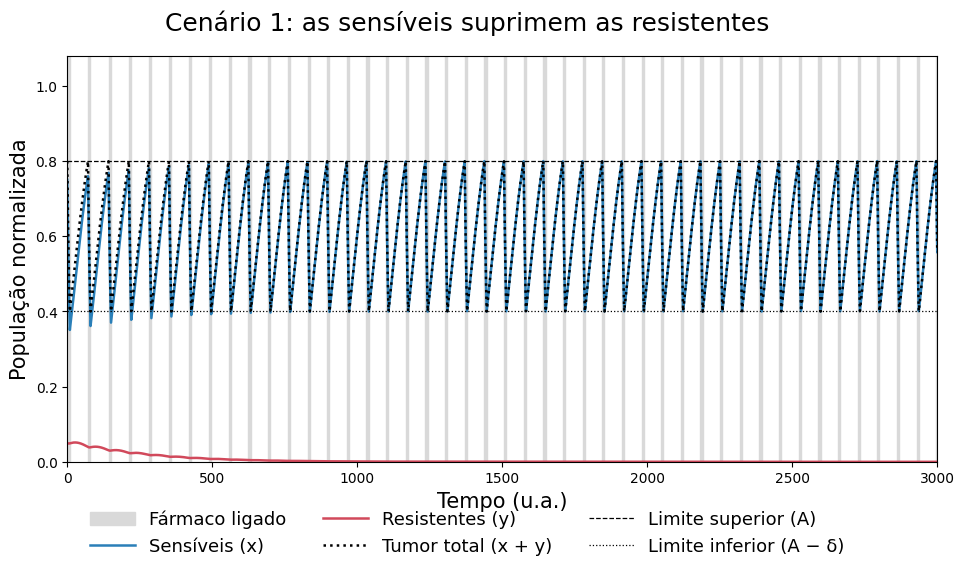

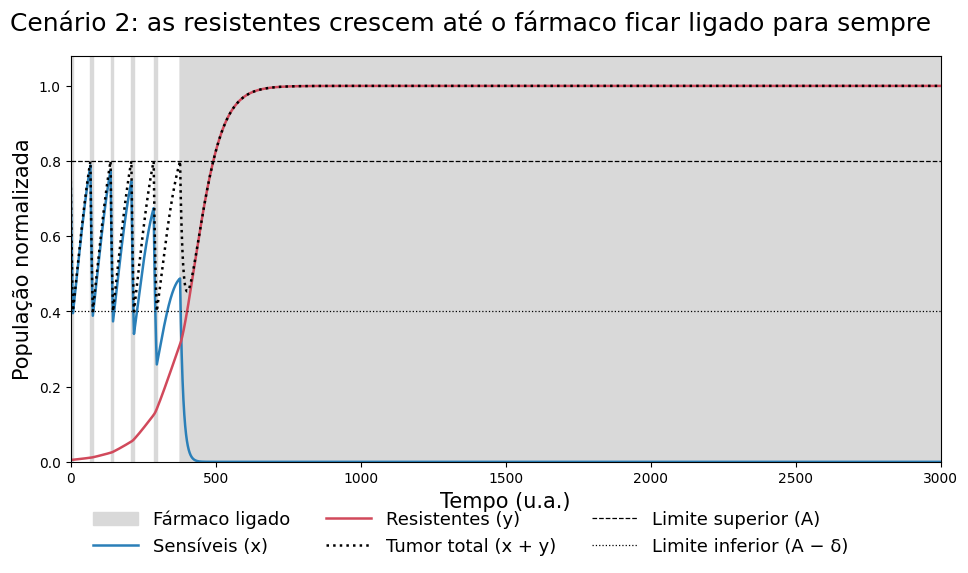

In [22]:
def fig_intermitente(p, y0, titulo, arq):
    s = simular(p, A - y0, y0, T_MAX, "intermitente")

    t, x, y, K = (s[k][::20] for k in ("t", "x", "y", "K"))

    fig, ax = plt.subplots(figsize=(10, 5.8))

    # Períodos em que o fármaco está ligado
    ax.fill_between(
        t, 0, 1,
        where=K > 0.5,
        transform=ax.get_xaxis_transform(),
        color="0.85",
        step="post",
        label="Fármaco ligado",
        zorder=0
    )

    # Populações
    ax.plot(t, x, c=c_x, lw=1.8, label="Sensíveis (x)")
    ax.plot(t, y, c=c_y, lw=1.8, label="Resistentes (y)")
    ax.plot(t, x + y, "k:", lw=1.8, label="Tumor total (x + y)")

    # Limiares
    ax.axhline(
        A, c="black", ls="--", lw=0.9,
        label="Limite superior (A)"
    )
    ax.axhline(
        A - delta, c="black", ls=":", lw=0.9,
        label="Limite inferior (A − δ)"
    )

    # Eixos
    ax.set(
        ylabel="População normalizada",
        xlabel="Tempo (u.a.)",
        ylim=(0, 1.08),
        xlim=(0, T_MAX)
    )

    ax.set_xlabel("Tempo (u.a.)", fontsize=15)
    ax.set_ylabel("População normalizada", fontsize=15)

    fig.suptitle(
        titulo,
        fontsize=18,
        y=0.98
    )

    handles, labels = ax.get_legend_handles_labels()

    fig.legend(
        handles, labels,
        loc="lower center",
        bbox_to_anchor=(0.5, 0.01),
        ncol=3,
        fontsize=13,
        frameon=False,
        columnspacing=2.,
        handlelength=2.5
    )

    fig.subplots_adjust(
        top=0.90,
        bottom=0.20,
        left=0.10,
        right=0.97
    )

    fig.savefig(
        f"{arq}.pdf",
        dpi=300,
        bbox_inches="tight",
        pad_inches=0.02
    )

    plt.show()
    plt.close(fig)


# Cenário 1
fig_intermitente(
    cen1,
    0.05,
    "Cenário 1: as sensíveis suprimem as resistentes",
    "fig4_intermitente_cenario1"
)

# Cenário 2
fig_intermitente(
    cen2,
    0.005,
    "Cenário 2: as resistentes crescem até o fármaco ficar ligado para sempre",
    "fig5_intermitente_cenario2"
)

## Planos de fases

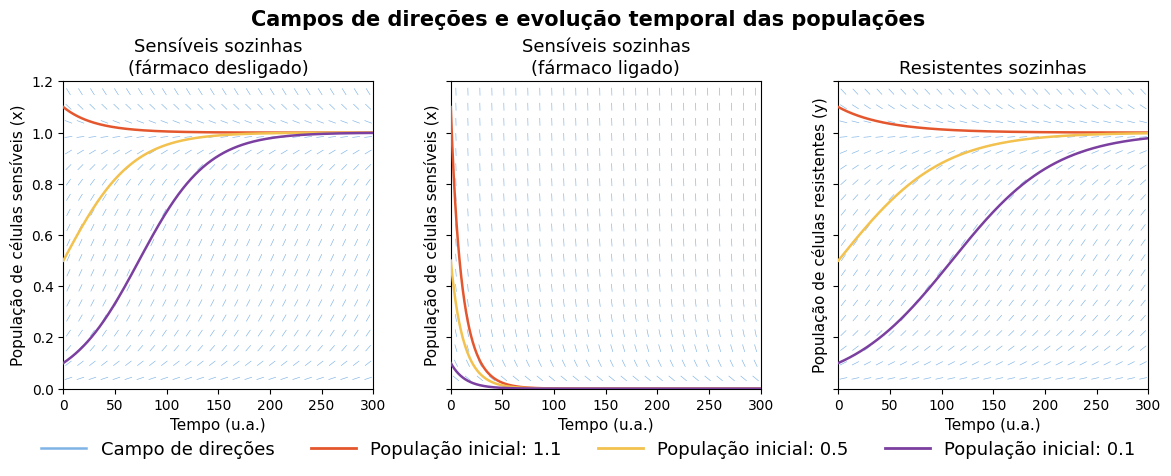

In [23]:
fig, axs = plt.subplots(
    1, 3,
    figsize=(14, 4.8),
    sharey=True
)

casos = [
    ("Sensíveis sozinhas\n(fármaco desligado)", "x", 0),
    ("Sensíveis sozinhas\n(fármaco ligado)", "x", 1),
    ("Resistentes sozinhas", "y", 0)
]

for ax, (tit, var, K) in zip(axs, casos):
    ax.set(
        xlim=(0, 300),
        ylim=(0, 1.2),
        title=tit,
        xlabel="Tempo (u.a.)"
    )

    ax.set_title(tit, fontsize=13)
    ax.set_xlabel("Tempo (u.a.)", fontsize=11)

    # Identificação da população no eixo y
    ax.set_ylabel(
        "População de células sensíveis (x)"
        if var == "x"
        else "População de células resistentes (y)",
        fontsize=11
    )


gt, gv = np.meshgrid(
    np.linspace(5, 295, 26),
    np.linspace(0.04, 1.16, 20)
)

p = cen1

cores = ["#e4572e", "#f2c14e", "#7b3fa0"]

condicoes_iniciais = [1.1, 0.5, 0.1]


for ax, (tit, var, K) in zip(axs, casos):

    inclinacao = (
        p["rx"] * gv * (1-gv) - K * p["rd"] * gv
        if var == "x"
        else p["ry"] * gv * (1-gv)
    )

    campo(ax, gt, gv, np.ones_like(gv), inclinacao)

    for v0, cor in zip(condicoes_iniciais, cores):

        s = (
            simular(p, v0, 0, 300, "sempre" if K else "sem")
            if var == "x"
            else simular(p, 0, v0, 300, "sem")
        )

        ax.plot(
            s["t"][::20],
            s[var][::20],
            color=cor,
            lw=1.8,
            zorder=3
        )

elementos_legenda = [
    Line2D(
        [0], [0],
        color="#7fb3e6",
        lw=1.8,
        label="Campo de direções"
    )
]

for v0, cor in zip(condicoes_iniciais, cores):

    elementos_legenda.append(
        Line2D(
            [0], [0],
            color=cor,
            lw=2,
            label=f"População inicial: {v0:.1f}"
        )
    )

fig.legend(
    handles=elementos_legenda,
    loc="lower center",
    bbox_to_anchor=(0.5, 0.01),
    ncol=4,
    fontsize=13,
    frameon=False,
    handlelength=2.5,
    columnspacing=2
)

fig.suptitle(
    "Campos de direções e evolução temporal das populações",
    fontsize=15,
    fontweight="bold",
    y=0.98
)

fig.subplots_adjust(
    top=0.83,
    bottom=0.19,
    wspace=0.25
)


plt.savefig(
    "resultados/fig9_campo_tempo.pdf",
    dpi=300,
    bbox_inches="tight",
    pad_inches=0.02
)

plt.show()
plt.close(fig)

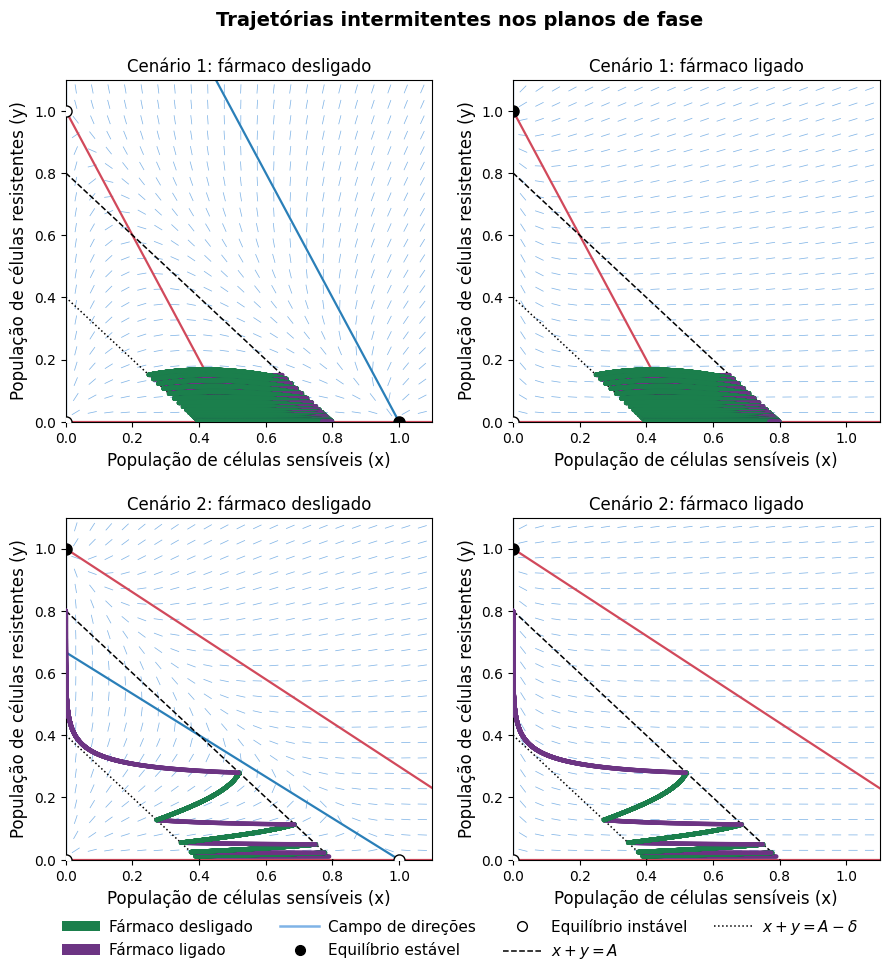

In [25]:
fig, axs = plt.subplots(2, 2, figsize=(10.5, 10))

titulos = [
    "Cenário 1: fármaco desligado",
    "Cenário 1: fármaco ligado",
    "Cenário 2: fármaco desligado",
    "Cenário 2: fármaco ligado"
]

preparar(axs, titulos, lim=1.1)

cmap = ListedColormap(["#1b7f4c", "#6c3483"])

g2 = np.linspace(0, 1.1, 5)

for i in range(2):
    axs[i, 0].set_ylabel(
        "População de células resistentes (y)",
        fontsize=12
    )

    axs[i, 1].set_ylabel("População de células resistentes (y)",
    fontsize=12)

    axs[i, 0].set_xlabel(
        "População de células sensíveis (x)",
        fontsize=12
    )
    axs[i, 1].set_xlabel(
        "População de células sensíveis (x)",
        fontsize=12
    )
    

for i, (p, y0) in enumerate([
    (cen1, 0.15),
    (cen2, 0.01)
]):

    s = simular(
        p, A - y0, y0, T_MAX,
        "intermitente",
        parar=True
    )

    for j, K in enumerate([0, 1]):

        ax = axs[i, j]

        plano_fase(ax, p, K, lim=1.1, legenda=False)

        # Trajetória intermitente
        ax.scatter(
            s["x"][::5],
            s["y"][::5],
            c=s["K"][::5],
            cmap=cmap,
            vmin=0,
            vmax=1,
            s=5,
            zorder=4
        )

        ax.plot(
            g2, A - g2,
            color="black",
            ls="--",
            lw=1.1
        )

        ax.plot(
            g2, A - delta - g2,
            color="black",
            ls=":",
            lw=1.1
        )


elementos = [

    # Estados do fármaco
    Patch(
        facecolor="#1b7f4c",
        label="Fármaco desligado"
    ),

    Patch(
        facecolor="#6c3483",
        label="Fármaco ligado"
    ),

    # Campo de direções
    Line2D(
        [0], [0],
        color="#7fb3e6",
        lw=1.8,
        label="Campo de direções"
    ),

    Line2D(
        [0], [0],
        marker="o",
        color="black",
        markerfacecolor="black",
        linestyle="None",
        markersize=7,
        label="Equilíbrio estável"
    ),

    Line2D(
        [0], [0],
        marker="o",
        color="black",
        markerfacecolor="white",
        linestyle="None",
        markersize=7,
        label="Equilíbrio instável"
    ),

    Line2D(
        [0], [0],
        color="black",
        ls="--",
        lw=1.1,
        label=r"$x+y=A$"
    ),

    Line2D(
        [0], [0],
        color="black",
        ls=":",
        lw=1.1,
        label=r"$x+y=A-\delta$"
    )
]

fig.legend(
    handles=elementos,
    loc="lower center",
    bbox_to_anchor=(0.5, 0.015),
    ncol=4,
    fontsize=11,
    frameon=False,
    columnspacing=1.8,
    handlelength=2.5,
    handletextpad=0.6
)

fig.suptitle(
    "Trajetórias intermitentes nos planos de fase",
    fontsize=14,
    fontweight="bold",
    y=0.98
)

fig.subplots_adjust(
    top=0.91,
    bottom=0.13,
    hspace=0.28,
    wspace=0.22
)

plt.savefig(
    "resultados/graf_C_trajetoria_intermitente.pdf",
    dpi=300,
    bbox_inches="tight",
    pad_inches=0.02
)

plt.show()